# Examples of Superposition 2: Superposition in Time

The original Theis solution assumes a pumping rate that starts at time 0 and continues forever. The Theis solution can be superposed *in time* to simulate the effect of variable pumping rates. Each time the pumping rate changes, a new Theis solution is superposed representing the change in flowrate.

We first demonstrate how the Theis solution can be shifted in time, and then demonstrate how to use this approach to superpose multiple solutions.

In [1]:
# GEOSCI-627 Class 15

#Import needed modules
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

from scipy.integrate import quad

In [2]:
#Definitions of all solutions to be used, each presented in terms of head change
#relative to an initial value. In addition to outputting the head change, 
#each function outputs the depth-integrated discharge (-T*dh/dx, -T*dh/dy)

def WellFunc(u):
    Wu = sp.special.exp1(u)
    return Wu

def Theis_dh(Q, T, S, xw, yw, x, y, t):
    r = ((x-xw)**2 + (y-yw)**2)**(1/2)
    u = (S*r**2)/(4*T*t)
    Wu = WellFunc(u)
    #the np.where function is used to return a drawdown of 0 before t = 0
    dh = np.where(u > 0, -Q/(4*np.pi*T)*Wu, 0)
    qix = np.where(u > 0, -Q/(2*np.pi)*((x-xw)/(r**2))*np.exp(-u), 0)
    qiy = np.where(u > 0, -Q/(2*np.pi)*((y-yw)/(r**2))*np.exp(-u), 0)
    return dh, qix, qiy

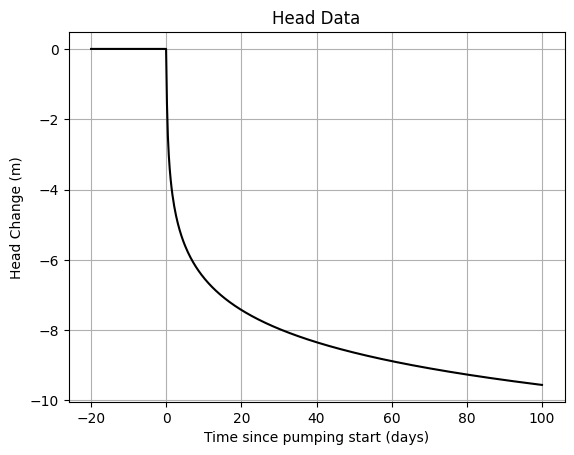

In [3]:
# Transient plot - drawdown at a given obs well location
t = np.linspace(-20,100,500) #days
xw, yw = 0, 0
xo, yo = 50,0

#True parameter values
K = 0.15 # m/day
Ss = 1e-5 # 1/m
b = 10 #m
T = K*b
S = Ss*b

#EDIT: Try changing t_start to see how the response changes
Q1 = 25 # m^3/day
t_start1 = 0
dh, _, _ = Theis_dh(Q1,T,S,xw,yw,xo,yo,(t-t_start1))

dd = -dh

fig, ax = plt.subplots()
ax.plot(t,dh, 'k')
ax.grid(visible='yes')
ax.set_xlabel('Time since pumping start (days)')
ax.set_ylabel('Head Change (m)')
ax.set_title('Head Data')
plt.show()



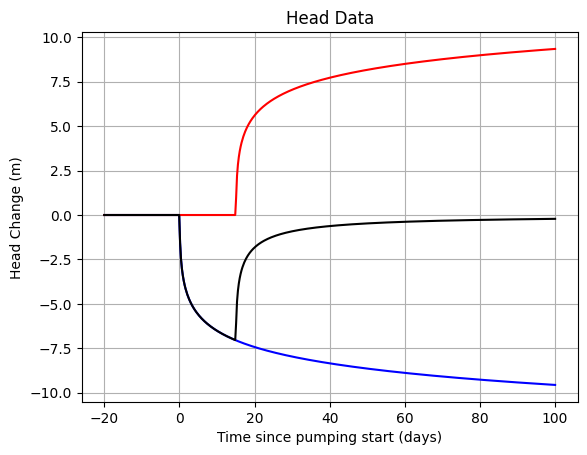

In [4]:
t = np.linspace(-20,100,500) #days
xw, yw = 0, 0
xo, yo = 50,0

#True parameter values
K = 0.15 # m/day
Ss = 1e-5 # 1/m
b = 10 #m
T = K*b
S = Ss*b

#EDIT: Try changing t_start to see how the response changes
Q1 = 25 # m^3/day
t_start1 = 0
dh1, _, _ = Theis_dh(Q1,T,S,xw,yw,xo,yo,(t-t_start1))

Q2 = -25 #m^3/day
t_start2 = 15
dh2, _, _ = Theis_dh(Q2,T,S,xw,yw,xo,yo,(t-t_start2))

dh_total = dh1+dh2
dd_total = -dh_total

fig, ax = plt.subplots()
ax.plot(t,dh1,'-b')
ax.plot(t,dh2,'-r')
ax.plot(t,dh_total, 'k')
ax.grid(visible='yes')
ax.set_xlabel('Time since pumping start (days)')
ax.set_ylabel('Head Change (m)')
ax.set_title('Head Data')
plt.show()

